# A small network for ice cream sales

A stall sells more ice cream the warmer the day, along an S-shaped curve. A small **neural network** learns this curve from $300$ days: it reads the temperature of a day and predicts how many ice creams the stall sells.

The days are synthetic: a folded cell below makes them up with a seeded random generator, so every run sees the same days.

**This is the worked example for the pufferfish exercise.** Two cells show their code, the network in part 2 and its training in part 3: they hold the three kinds of lines the exercise asks for. The other cells make up the days and draw them, so Colab shows only their titles. Run them as they are; the Show code button opens one if you are curious.

In [1]:
#@title Imports { display-mode: "form" }
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

## 1. Made-up data

Each day has two numbers: its temperature, between $5$ and $35$ degrees Celsius, and the ice creams the stall sold, between $0$ and $400$, which is all it brings each day. Cold days sell almost nothing, around $20$ degrees the sales climb steeply, and on hot days the stall sells out. Luck adds some noise to every day.

The network counts the temperature in tens of degrees above or below $20$, and the sales in hundreds of ice creams: for it, a day of $23$ degrees is $0.3$, a day of $12$ degrees is $-0.8$, and $250$ ice creams are $2.5$. A network learns fastest from small numbers like these. In the code, `x` holds the $300$ temperatures and `y` the $300$ sales, both counted this way.

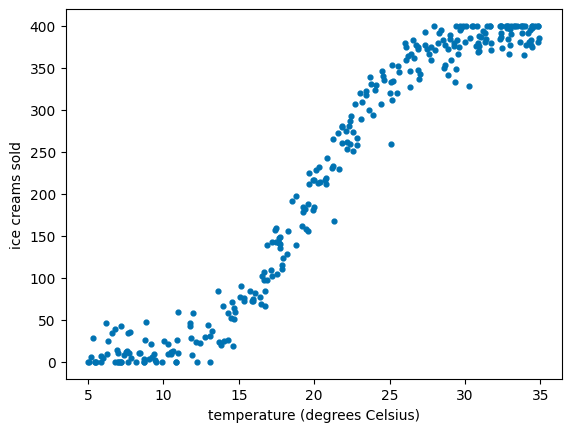

In [2]:
#@title Three hundred made-up days { display-mode: "form" }
rng = np.random.default_rng(seed=0)   # seeded: the same 300 days on every computer
n = 300                               # the number of days

temperature = rng.uniform(low=5, high=35, size=n)   # one temperature per day, in degrees

# The average sales on a day with this temperature: an S shape, a few ice creams when it
# is cold, 200 at 20 degrees, and close to the stall's 400 when it is hot.
average_sales = 400 / (1 + np.exp(-(temperature - 20) / 3))
luck = rng.normal(loc=0, scale=20, size=n)                # the noise: a bit above or below each day
sales = np.clip(np.round(average_sales + luck), 0, 400)   # whole ice creams, at most the 400 it has

plt.scatter(temperature, sales, s=12, color="#0072B2")
plt.xlabel("temperature (degrees Celsius)")
plt.ylabel("ice creams sold")
plt.show()

# A network reads a table with one row per day and one column per number, so each list
# of n numbers becomes a column of shape (n, 1). It learns fastest from small numbers, so it
# counts in tens of degrees above or below 20, and in hundreds of ice creams.
x = torch.tensor((temperature - 20) / 10, dtype=torch.float32).reshape(n, 1)   # what the network reads
y = torch.tensor(sales / 100, dtype=torch.float32).reshape(n, 1)               # what it should predict

## 2. The model

The network reads one number, the temperature, and gives back one number, its prediction for the ice creams sold. In between sit two **hidden layers** of $32$ numbers each. Each hidden layer is one line of the code below: an `nn.Linear`, which computes with weights that training adjusts, followed by an `nn.ReLU`, which turns every negative number into $0$. These bends let the network follow a curve.

In [ ]:
torch.manual_seed(0)   # seeded: the same starting weights on every computer

# One line is one layer: an nn.Linear, then an nn.ReLU. nn.Linear(a, b) takes a numbers in
# and gives b numbers out, so each line takes in as many numbers as the line above gives out.
# The last line has no nn.ReLU: its numbers are the answer.
model = nn.Sequential(
    nn.Linear(1, 32), nn.ReLU(),     # 1 number in (the temperature), 32 numbers out
    nn.Linear(32, 32), nn.ReLU(),    # 32 numbers in (from the line above), 32 numbers out
    nn.Linear(32, 1),                # 32 numbers in, 1 number out: the prediction
)

## 3. Training

The loop of weekend 1: while the miss is too big, take a step. The miss is the squared difference between the predicted and the true sales, averaged over all $300$ days. It is counted in hundreds of ice creams, like `y`, so the threshold $0.031$ is a typical miss of about $0.18$ hundreds, $18$ ice creams a day, since $0.18 \times 0.18$ is about $0.031$. That is about what luck alone causes: the days scatter around the true curve by about as much. No curve brings the miss down to $0$, and a threshold below the noise takes very long to reach.

In [ ]:
# An optimizer changes the weights of the model a little at every step, to shrink the miss.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)   # lr: how big a step is

loss = 1.0                                   # any start above the threshold
while loss > 0.031:
    loss = ((model(x) - y) ** 2).mean()      # the average squared miss
    optimizer.zero_grad()                    # forget the gradients of the previous step
    loss.backward()                          # compute the gradient of the loss
    optimizer.step()                         # move every weight a small step against its gradient
    print(f"\raverage squared miss: {loss.item():.4f}", end="")

## 4. What the network learned

The folded cell below draws the $300$ made-up days as dots and the network's prediction for every temperature from $5$ to $35$ degrees as a curve. Nobody told the network the rule that made the days: it found the S shape from the dots alone.

In [ ]:
#@title The network's curve { display-mode: "form" }
# The prediction for 100 temperatures from 5 to 35 degrees. The network reads tens of
# degrees above or below 20 and answers in hundreds of ice creams, so the temperatures go
# in counted that way and the answers come out times 100. detach() drops the bookkeeping
# of training, so matplotlib can draw the numbers.
grid = torch.linspace(5, 35, 100).reshape(100, 1)
curve = model((grid - 20) / 10).detach() * 100

plt.scatter(temperature, sales, s=12, color="#0072B2", label="300 made-up days")
plt.plot(grid, curve, color="#D55E00", linewidth=2.5, label="the network")
plt.xlabel("temperature (degrees Celsius)")
plt.ylabel("ice creams sold")
plt.legend()
plt.show()

## The three patterns in words

* **A layer** is one line inside `nn.Sequential`: `nn.Linear(a, b), nn.ReLU(),`. The number `a` says how many numbers come in, the number `b` how many come out, and the `b` of one line is the `a` of the next. The last line has no `nn.ReLU()`.
* **The optimizer** is created once, before the loop, from the weights of the model and the size of a step: `optimizer = torch.optim.Adam(model.parameters(), lr=0.01)`.
* **A training step** is three calls inside the loop, always in this order: `optimizer.zero_grad()` forgets the old gradients, `loss.backward()` computes the new ones, and `optimizer.step()` moves the weights.